In [1]:
import pandas as pd

In [4]:
# Define the path to your new dataset
csv_file_path2 = "All_features/UNSW_2018_IoT_Botnet_Full5pc_4.csv"
df = pd.read_csv(csv_file_path2)  # đổi tên file

print(df.shape)
print(df.head())
print(df.info())

C:\Users\owner\AppData\Local\Temp\ipykernel_24276\1843043468.py:3: DtypeWarning: Columns (7,9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_file_path2)  # đổi tên file


(668522, 46)
   pkSeqID         stime flgs  flgs_number proto  proto_number  \
0  3000001  1.528099e+09    e            1   udp             3   
1  3000002  1.528099e+09    e            1   udp             3   
2  3000003  1.528099e+09    e            1   udp             3   
3  3000004  1.528099e+09    e            1   udp             3   
4  3000005  1.528099e+09    e            1   udp             3   

             saddr sport          daddr dport  ...  AR_P_Proto_P_DstIP  \
0  192.168.100.147  6226  192.168.100.3    80  ...             1.09825   
1  192.168.100.147  6227  192.168.100.3    80  ...             1.09825   
2  192.168.100.147  6228  192.168.100.3    80  ...             1.09825   
3  192.168.100.147  6229  192.168.100.3    80  ...             1.09825   
4  192.168.100.147  6230  192.168.100.3    80  ...             1.09825   

   N_IN_Conn_P_DstIP N_IN_Conn_P_SrcIP  AR_P_Proto_P_Sport  \
0                100               100             1.09827   
1                100 

In [5]:
category_counts = df['category'].value_counts()
print("Number of unique categories:", len(category_counts))
display(category_counts)

Number of unique categories: 4


category
DDoS              576884
Reconnaissance     91082
Normal               477
Theft                 79
Name: count, dtype: int64

### Handling Class Imbalance with Resampling

Given the severe class imbalance, we'll employ resampling techniques to create a more balanced dataset. This often helps machine learning models perform better, especially on minority classes. We'll use the `imblearn` library for this purpose.

In [6]:
# Install imbalanced-learn if not already installed
# !pip install imbalanced-learn

In [7]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
import pandas as pd

# Separate features (X) and target (y)
X = df.drop('category', axis=1)
y = df['category']

print("Original class distribution:")
display(y.value_counts())

Original class distribution:


category
DDoS              1926624
DoS               1650260
Reconnaissance      91082
Normal                477
Theft                  79
Name: count, dtype: int64

#### Downsampling Majority Classes

We'll start by downsampling the extremely large classes like 'DDoS' and 'DoS' to a more manageable number. `RandomUnderSampler` is a simple method that randomly removes samples from the majority class.

In [8]:
# Define the target counts for downsampling.
# For demonstration, let's aim to bring the majority classes closer, but not necessarily equal to the minority.
# We can adjust these ratios based on experimentation.
# For example, let's try to reduce DDoS significantly, while keeping others as they are for now.
# Note: This is an example, the exact ratios might need tuning.

# First, identify the classes to undersample
# Let's say we want to reduce DDoS to around 100,000 samples initially.
# And keep Reconnaissance as is (91082) as a threshold for oversampling.

# Define the sampling strategy for RandomUnderSampler
# We'll undersample DDoS to a level closer to Reconnaissance.
# For simplicity, let's set a target of 100,000 samples for DDoS.

sampling_strategy_under = {
    'DDoS': 100000,
    'DoS': 100000,
    'Reconnaissance': 91082, # Keep as is, or slightly adjust
    'Normal': 477,
    'Theft': 79
}

# Ensure that the sampling strategy does not try to undersample a class below its current count
for cls, count in y.value_counts().items():
    if cls in sampling_strategy_under and sampling_strategy_under[cls] > count:
        sampling_strategy_under[cls] = count # Keep current count if target is higher

rus = RandomUnderSampler(sampling_strategy=sampling_strategy_under, random_state=42)
X_resampled_under, y_resampled_under = rus.fit_resample(X, y)

print("Class distribution after RandomUnderSampler (Downsampling):")
display(y_resampled_under.value_counts())

Class distribution after RandomUnderSampler (Downsampling):


category
DDoS              100000
DoS               100000
Reconnaissance     91082
Normal               477
Theft                 79
Name: count, dtype: int64

#### Upsampling Minority Classes with SMOTE

Now, we'll use `SMOTE` (Synthetic Minority Over-sampling Technique) to generate synthetic samples for the minority classes like 'Normal' and 'Theft'. SMOTE works by creating new samples based on the existing minority class samples, helping to increase their representation without simply duplicating them.

**Note**: SMOTE is designed for numerical data. If your features `X` contain categorical columns, you might need to encode them (e.g., using one-hot encoding) before applying SMOTE, or use a variant like `SMOTENC` if `imblearn` is installed with the appropriate version.

In [9]:
# For SMOTE, we typically want to upsample to a similar level as the downsampled majority classes,
# or to a level that provides a good balance.
# Let's aim to bring 'Normal' and 'Theft' up to a count closer to 'Reconnaissance' or the downsampled majority.
# We'll use the 'Reconnaissance' count as a potential target for upsampling for now.

# Use the current counts after undersampling to define SMOTE strategy
counts_after_under = y_resampled_under.value_counts()
sampling_strategy_over = {
    'DDoS': counts_after_under.get('DDoS', 0),
    'DoS': counts_after_under.get('DoS', 0),
    'Reconnaissance': counts_after_under.get('Reconnaissance', 0),
    'Normal': 50000, # Example target for Normal, can be adjusted
    'Theft': 50000    # Example target for Theft, can be adjusted
}

# Ensure that SMOTE only targets classes below the desired threshold
# For SMOTE, the target count should be greater than or equal to the current count.
for cls, count in counts_after_under.items():
    if cls in sampling_strategy_over and sampling_strategy_over[cls] < count:
        sampling_strategy_over[cls] = count # Don't downsample with SMOTE

# Filter out classes that are already above the target or don't need oversampling
sampling_strategy_over_final = {cls: target_count for cls, target_count in sampling_strategy_over.items() if counts_after_under.get(cls, 0) < target_count}

# Ensure X has only numerical features before applying SMOTE
# For simplicity, if there are non-numeric columns, they need to be handled (e.g., one-hot encoded or dropped)
# Let's try to convert non-numeric columns to numeric for now or drop them if they can't be converted.

X_numeric = X_resampled_under.select_dtypes(include=['number'])
y_numeric = y_resampled_under

if not X_numeric.empty:
    smote = SMOTE(sampling_strategy=sampling_strategy_over_final, random_state=42)
    X_resampled_final, y_resampled_final = smote.fit_resample(X_numeric, y_numeric)

    print("Class distribution after SMOTE (Upsampling):")
    display(y_resampled_final.value_counts())
else:
    print("Warning: No numeric features found after downsampling. SMOTE requires numeric data. Skipping SMOTE.")
    X_resampled_final = X_resampled_under
    y_resampled_final = y_resampled_under


Class distribution after SMOTE (Upsampling):


category
DDoS              100000
DoS               100000
Reconnaissance     91082
Normal             50000
Theft              50000
Name: count, dtype: int64

### Combined Resampled Dataset

After both downsampling and upsampling, the dataset is more balanced. You can now use `X_resampled_final` and `y_resampled_final` for training your machine learning model. Remember to validate your model using appropriate metrics (precision, recall, F1-score) on a test set that reflects the original imbalance, or on a test set that has been similarly processed.

### Cross-Validation on Original Imbalanced Dataset

To understand the impact of resampling, let's also perform cross-validation on the original, imbalanced dataset. This will highlight the challenges faced by models when dealing with highly skewed class distributions and provide a baseline for comparison.

In [10]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Select only numeric features from the original DataFrame X
X_original_numeric = X.select_dtypes(include=['number'])

# Initialize a classifier (e.g., Logistic Regression)
model_original = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)

# Initialize StratifiedKFold
# n_splits is the number of folds (e.g., 5 or 10 are common)
# Note: StratifiedKFold will try to preserve class distribution, but for highly imbalanced data,
# some folds might not contain all classes, especially if n_splits is large and minority classes are very small.
skf_original = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Lists to store scores for each fold
accuracy_scores_original = []
precision_scores_original = []
recall_scores_original = []
f1_scores_original = []

print("Starting Cross-Validation on Original Data...")

# Iterate through each fold
for fold, (train_index, test_index) in enumerate(skf_original.split(X_original_numeric, y)):
    X_train_original, X_test_original = X_original_numeric.iloc[train_index], X_original_numeric.iloc[test_index]
    y_train_original, y_test_original = y.iloc[train_index], y.iloc[test_index]

    # Train the model
    model_original.fit(X_train_original, y_train_original)

    # Make predictions
    y_pred_original = model_original.predict(X_test_original)

    # Calculate metrics
    # Use zero_division=0 to handle cases where a class has no predicted samples, avoiding warnings/errors.
    accuracy_original = accuracy_score(y_test_original, y_pred_original)
    precision_original = precision_score(y_test_original, y_pred_original, average='weighted', zero_division=0)
    recall_original = recall_score(y_test_original, y_pred_original, average='weighted', zero_division=0)
    f1_original = f1_score(y_test_original, y_pred_original, average='weighted', zero_division=0)

    accuracy_scores_original.append(accuracy_original)
    precision_scores_original.append(precision_original)
    recall_scores_original.append(recall_original)
    f1_scores_original.append(f1_original)

    print(f"\n--- Fold {fold + 1} (Original Data) ---")
    print(f"Accuracy: {accuracy_original:.4f}")
    print(f"Precision: {precision_original:.4f}")
    print(f"Recall: {recall_original:.4f}")
    print(f"F1-Score: {f1_original:.4f}")

print("\n--- Average Cross-Validation Scores (Original Data) ---")
print(f"Average Accuracy: {np.mean(accuracy_scores_original):.4f} (+/- {np.std(accuracy_scores_original):.4f})")
print(f"Average Precision: {np.mean(precision_scores_original):.4f} (+/- {np.std(precision_scores_original):.4f})")
print(f"Average Recall: {np.mean(recall_scores_original):.4f} (+/- {np.std(recall_scores_original):.4f})")
print(f"Average F1-Score: {np.mean(f1_scores_original):.4f} (+/- {np.std(f1_scores_original):.4f})")

Starting Cross-Validation on Original Data...


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 1 (Original Data) ---
Accuracy: 0.7891
Precision: 0.7885
Recall: 0.7891
F1-Score: 0.7754


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 2 (Original Data) ---
Accuracy: 0.7893
Precision: 0.7883
Recall: 0.7893
F1-Score: 0.7758


...


--- Fold 3 (Original Data) ---
Accuracy: 0.7882
Precision: 0.8123
Recall: 0.7882
F1-Score: 0.7746


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 4 (Original Data) ---
Accuracy: 0.7891
Precision: 0.7882
Recall: 0.7891
F1-Score: 0.7755


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 5 (Original Data) ---
Accuracy: 0.7883
Precision: 0.7879
Recall: 0.7883
F1-Score: 0.7747

--- Average Cross-Validation Scores (Original Data) ---
Average Accuracy: 0.7888 (+/- 0.0005)
Average Precision: 0.7930 (+/- 0.0096)
Average Recall: 0.7888 (+/- 0.0005)
Average F1-Score: 0.7752 (+/- 0.0005)


### Cross-Validation for Model Evaluation

After balancing the dataset, it's essential to evaluate model performance using cross-validation. This helps to get a more robust estimate of how the model will perform on unseen data and to detect potential overfitting. We will use `StratifiedKFold` to ensure that each fold maintains the class distribution of the balanced dataset.

In [11]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Assuming X_resampled_final and y_resampled_final are your balanced dataset
# X_resampled_final contains only numerical features, which is suitable for Logistic Regression.

# Initialize a classifier (e.g., Logistic Regression)
# We'll use a simple solver and max_iter for demonstration, these might need tuning
model = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)

# Initialize StratifiedKFold
# n_splits is the number of folds (e.g., 5 or 10 are common)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Lists to store scores for each fold
accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

print("Starting Cross-Validation...")

for fold, (train_index, test_index) in enumerate(skf.split(X_resampled_final, y_resampled_final)):
    X_train, X_test = X_resampled_final.iloc[train_index], X_resampled_final.iloc[test_index]
    y_train, y_test = y_resampled_final.iloc[train_index], y_resampled_final.iloc[test_index]

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    accuracy_scores.append(accuracy)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

    print(f"\n--- Fold {fold + 1} ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

print("\n--- Average Cross-Validation Scores ---")
print(f"Average Accuracy: {np.mean(accuracy_scores):.4f} (+/- {np.std(accuracy_scores):.4f})")
print(f"Average Precision: {np.mean(precision_scores):.4f} (+/- {np.std(precision_scores):.4f})")
print(f"Average Recall: {np.mean(recall_scores):.4f} (+/- {np.std(recall_scores):.4f})")
print(f"Average F1-Score: {np.mean(f1_scores):.4f} (+/- {np.std(f1_scores):.4f})")

Starting Cross-Validation...


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 1 ---
Accuracy: 0.7311
Precision: 0.7858
Recall: 0.7311
F1-Score: 0.6851


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 2 ---
Accuracy: 0.7314
Precision: 0.7861
Recall: 0.7314
F1-Score: 0.6857


...


--- Fold 3 ---
Accuracy: 0.7296
Precision: 0.7826
Recall: 0.7296
F1-Score: 0.6834


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 4 ---
Accuracy: 0.7302
Precision: 0.7843
Recall: 0.7302
F1-Score: 0.6843


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



--- Fold 5 ---
Accuracy: 0.7301
Precision: 0.7829
Recall: 0.7301
F1-Score: 0.6843

--- Average Cross-Validation Scores ---
Average Accuracy: 0.7305 (+/- 0.0007)
Average Precision: 0.7843 (+/- 0.0015)
Average Recall: 0.7305 (+/- 0.0007)
Average F1-Score: 0.6846 (+/- 0.0008)


### Tải và Khám phá Dữ liệu Mới (EDA)

In [43]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import LabelEncoder
import numpy as np

In [44]:
# Define the path to your new dataset
csv_file_path2 = '../All_features/UNSW_2018_IoT_Botnet_Full5pc_4.csv'

# Load the dataset
df2 = pd.read_csv(csv_file_path2)

print(f"Dataset loaded from: {csv_file_path2}")
display(df2.head())

C:\Users\owner\AppData\Local\Temp\ipykernel_712\4033507765.py:5: DtypeWarning: Columns (7,9) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv(csv_file_path2)


Dataset loaded from: ../All_features/UNSW_2018_IoT_Botnet_Full5pc_4.csv


,pkSeqID,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,...,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,category,subcategory
0,3000001,1.528099e+09,e,1,udp,3,192.168.100.147,6226,192.168.100.3,80,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
1,3000002,1.528099e+09,e,1,udp,3,192.168.100.147,6227,192.168.100.3,80,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
2,3000003,1.528099e+09,e,1,udp,3,192.168.100.147,6228,192.168.100.3,80,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
3,3000004,1.528099e+09,e,1,udp,3,192.168.100.147,6229,192.168.100.3,80,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
4,3000005,1.528099e+09,e,1,udp,3,192.168.100.147,6230,192.168.100.3,80,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP


In [45]:
print("--- Thông tin DataFrame --- ")
print(df2.info())

print("\n--- Kích thước DataFrame --- ")
display(df2.shape)

print("\n--- Giá trị thiếu (Missing Values) --- ")
# Display only columns with missing values
missing_values = df2.isnull().sum()
display(missing_values[missing_values > 0])

--- Thông tin DataFrame --- 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 668522 entries, 0 to 668521
Data columns (total 46 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   pkSeqID                           668522 non-null  int64  
 1   stime                             668522 non-null  float64
 2   flgs                              668522 non-null  object 
 3   flgs_number                       668522 non-null  int64  
 4   proto                             668522 non-null  object 
 5   proto_number                      668522 non-null  int64  
 6   saddr                             668522 non-null  object 
 7   sport                             668522 non-null  object 
 8   daddr                             668522 non-null  object 
 9   dport                             668522 non-null  object 
 10  pkts                              668522 non-null  int64  
 11  bytes                  

(668522, 46)


--- Giá trị thiếu (Missing Values) --- 


Series([], dtype: int64)

In [46]:
# 'Unnamed: 0' and 'pkSeqID' are typically identifier columns and may not be useful as features.
# We will drop them for feature selection.
columns_to_drop = []
if 'Unnamed: 0' in df2.columns:
    columns_to_drop.append('Unnamed: 0')
if 'pkSeqID' in df2.columns:
    columns_to_drop.append('pkSeqID')

if columns_to_drop:
    df2 = df2.drop(columns=columns_to_drop)
    print(f"Đã loại bỏ các cột định danh: {', '.join(columns_to_drop)}")
else:
    print("Không tìm thấy cột định danh 'Unnamed: 0' hoặc 'pkSeqID' để loại bỏ.")

print("DataFrame sau khi loại bỏ cột định danh (head):")
display(df2.head())

Đã loại bỏ các cột định danh: pkSeqID
DataFrame sau khi loại bỏ cột định danh (head):


,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,pkts,...,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,category,subcategory
0,1.528099e+09,e,1,udp,3,192.168.100.147,6226,192.168.100.3,80,15,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
1,1.528099e+09,e,1,udp,3,192.168.100.147,6227,192.168.100.3,80,15,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
2,1.528099e+09,e,1,udp,3,192.168.100.147,6228,192.168.100.3,80,15,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
3,1.528099e+09,e,1,udp,3,192.168.100.147,6229,192.168.100.3,80,15,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP
4,1.528099e+09,e,1,udp,3,192.168.100.147,6230,192.168.100.3,80,15,...,1.09825,100,100,1.09827,1.09825,1500,1500,1,DDoS,UDP


In [47]:
print("--- Thống tháp mô tả cho các cột số --- ")
display(df2.describe())

--- Thống tháp mô tả cho các cột số --- 


,stime,flgs_number,proto_number,pkts,bytes,state_number,ltime,seq,dur,mean,...,TnP_Per_Dport,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack
count,6.685220e+05,668522.000000,668522.00000,668522.000000,6.685220e+05,668522.000000,6.685220e+05,668522.000000,668522.000000,668522.000000,...,668522.000000,6.685220e+05,668522.000000,668522.000000,668522.000000,6.685220e+05,6.685220e+05,668522.000000,668522.000000,668522.000000
mean,1.527874e+09,1.087990,2.81228,10.912461,2.039721e+03,3.761715,1.527874e+09,115211.175598,13.440747,2.943216,...,904.502742,1.820480e+03,1558.805372,97.742857,81.869814,2.500591e+03,2.949491e+03,920.568680,775.625785,0.999286
std,5.722060e+05,0.645593,0.61694,270.233917,2.629841e+05,0.900487,5.722058e+05,78683.515047,43.448549,1.255335,...,1350.237211,1.976339e+04,9492.700037,12.300795,26.268537,3.349035e+04,3.667689e+04,655.730587,615.060700,0.026702
min,1.526344e+09,1.000000,1.00000,1.000000,6.000000e+01,1.000000,1.526344e+09,1.000000,0.000000,0.000000,...,1.000000,0.000000e+00,0.000000,1.000000,1.000000,0.000000e+00,0.000000e+00,1.000000,1.000000,0.000000
25%,1.528099e+09,1.000000,3.00000,7.000000,4.200000e+02,4.000000,1.528099e+09,37791.250000,12.220725,2.712587,...,700.000000,5.654380e-01,0.575499,100.000000,68.000000,5.720700e-01,5.754470e-01,700.000000,476.000000,1.000000
50%,1.528099e+09,1.000000,3.00000,8.000000,4.800000e+02,4.000000,1.528099e+09,117287.000000,13.658235,3.404960,...,900.000000,7.973740e-01,0.796360,100.000000,100.000000,7.978010e-01,7.962820e-01,904.000000,700.000000,1.000000
75%,1.528099e+09,1.000000,3.00000,12.000000,7.800000e+02,4.000000,1.528099e+09,178593.750000,13.957514,3.684863,...,1206.000000,1.074320e+00,1.037430,100.000000,100.000000,1.074630e+00,1.034220e+00,1213.000000,1100.000000,1.000000
max,1.529381e+09,9.000000,5.00000,70057.000000,7.183334e+07,11.000000,1.529382e+09,262161.000000,2771.485107,4.981882,...,244425.000000,2.714290e+06,1000000.000000,100.000000,100.000000,3.000000e+06,2.000000e+06,112544.000000,117939.000000,1.000000


In [37]:
print("--- Phân tích các cột phân loại (Object/Categorical) --- ")
categorical_cols_eda = df2.select_dtypes(include=['object']).columns

if not categorical_cols_eda.empty:
    for col in categorical_cols_eda:
        print(f"\nValue counts cho cột '{col}':")
        display(df2[col].value_counts())
else:
    print("Không tìm thấy cột phân loại nào trong DataFrame.")

--- Phân tích các cột phân loại (Object/Categorical) --- 

Value counts cho cột 'flgs':


flgs
e        654807
eU        11159
e s        2331
e d         113
e g          99
e &           5
e   t         4
e *           3
e  D          1
Name: count, dtype: int64


Value counts cho cột 'proto':


proto
udp          592145
tcp           67202
icmp           9030
arp             137
ipv6-icmp         8
Name: count, dtype: int64


Value counts cho cột 'saddr':


...

state
INT    591914
RST     59975
URP      8928
FIN      6385
REQ       758
CON       452
ECO        70
TST        16
MAS        16
NRS         8
Name: count, dtype: int64


Value counts cho cột 'category':


category
DDoS              576884
Reconnaissance     91082
Normal               477
Theft                 79
Name: count, dtype: int64


Value counts cho cột 'subcategory':


subcategory
UDP                  576884
Service_Scan          73168
OS_Fingerprint        17914
Normal                  477
Keylogging               73
Data_Exfiltration         6
Name: count, dtype: int64

In [48]:
# Chuyển các cột string sang số sau khi phân tích các cột phân loại.
string_cols = df2.select_dtypes(include=['object']).columns
if len(string_cols) > 0:
    print('Converting string columns to numeric for:', list(string_cols))
    for col in string_cols:
        df2[col] = pd.factorize(df2[col])[0]
    print('Conversion complete. Sample values:')
    display(df2[string_cols].head())
else:
    print('No string columns found to convert.')

Converting string columns to numeric for: ['flgs', 'proto', 'saddr', 'sport', 'daddr', 'dport', 'state', 'category', 'subcategory']
Conversion complete. Sample values:


,flgs,proto,saddr,sport,daddr,dport,state,category,subcategory
0,0,0,0,0,0,0,0,0,0
1,0,0,0,1,0,0,0,0,0
2,0,0,0,2,0,0,0,0,0
3,0,0,0,3,0,0,0,0,0
4,0,0,0,4,0,0,0,0,0


In [50]:
string_cols = df2.select_dtypes(include=['object']).columns
for col in string_cols:
    print(col, df2[col].nunique(dropna=False))
    print(df2[col].value_counts().head(10))
    print()

(668522, 45)
['stime', 'flgs', 'flgs_number', 'proto', 'proto_number', 'saddr', 'sport', 'daddr', 'dport', 'pkts', 'bytes', 'state', 'state_number', 'ltime', 'seq', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP', 'attack', 'category', 'subcategory']
Top 30 features by absolute correlation to target:
['subcategory', 'ltime', 'stime', 'max', 'mean', 'proto', 'state', 'proto_number', 'dport', 'state_number', 'stddev', 'sport', 'seq', 'min', 'daddr', 'N_IN_Conn_P_DstIP', 'AR_P_Proto_P_DstIP', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP', 'flgs_number', 'sum', 'flgs', 'N_IN_Conn_P_SrcIP', 'TnP_Per_Dport', 'AR_P_Proto_P_Src

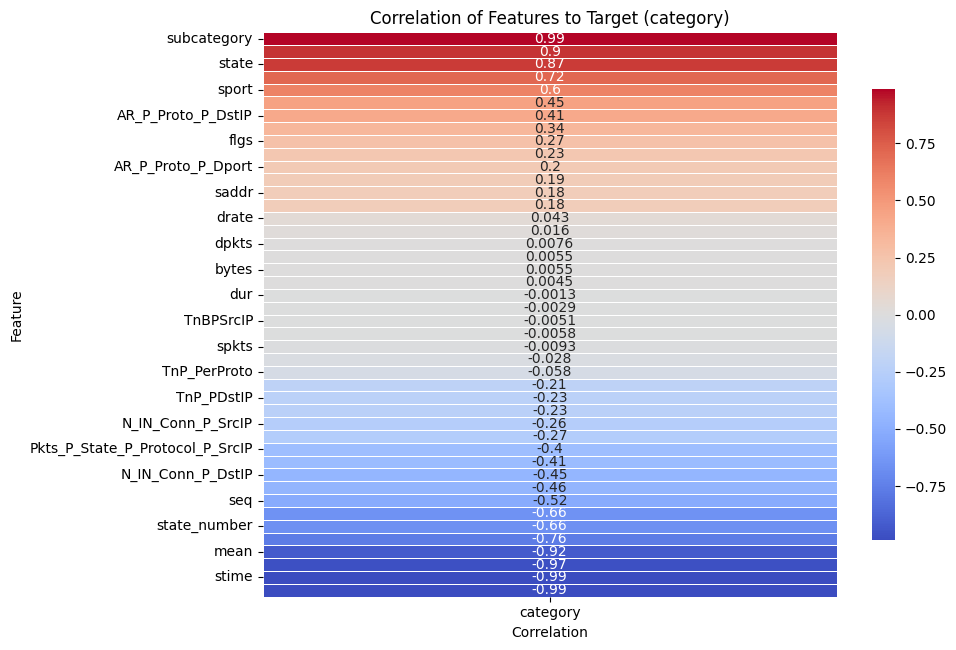

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

# Encode non-numeric features and the target for correlation analysis.
print(df2.shape)
print(df2.columns.tolist())
df_corr = df2.copy()
for col in df_corr.columns:
    if not pd.api.types.is_numeric_dtype(df_corr[col]):
        df_corr[col] = pd.factorize(df_corr[col])[0]

# Determine target encoding and compute correlations with all features.
target_col = 'category'
if target_col not in df_corr.columns:
    raise ValueError(f"Target column '{target_col}' not found in DataFrame")

corr_with_target = df_corr.corr()[target_col].drop(target_col)
corr_with_target = corr_with_target.sort_values(ascending=False)

# Create feature groups by highest absolute correlation to the target.
# We use absolute value to capture strong relationships in either direction.
abs_corr = corr_with_target.abs().sort_values(ascending=False)

top30_features = abs_corr.head(30).index.tolist()
top20_features = abs_corr.head(20).index.tolist()
top10_features = abs_corr.head(10).index.tolist()

print('Top 30 features by absolute correlation to target:')
print(top30_features)
print('\nTop 20 features by absolute correlation to target:')
print(top20_features)
print('\nTop 10 features by absolute correlation to target:')
print(top10_features)

plt.figure(figsize=(10, max(6, len(corr_with_target) * 0.15)))
sns.heatmap(corr_with_target.to_frame(), annot=True, cmap='coolwarm', center=0,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation of Features to Target (category)')
plt.xlabel('Correlation')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Lựa chọn đặc trưng (Feature Selection)

Chúng ta sẽ chuẩn bị dữ liệu bằng cách mã hóa các đặc trưng phân loại và sau đó sử dụng `SelectKBest` với kiểm định `f_classif` để chọn ra các đặc trưng quan trọng nhất.

In [51]:
# Tách đặc trưng (X) và biến mục tiêu (y)
X2 = df2.drop('category', axis=1)
y2 = df2['category']

print("Đặc trưng ban đầu (X2) head:")
display(X2.head())
print("\nBiến mục tiêu ban đầu (y2) head:")
display(y2.head())

# Xác định các cột phân loại
categorical_cols = X2.select_dtypes(include=['object', 'category']).columns
print(f"\nCác cột phân loại được xác định: {list(categorical_cols)}")

if len(categorical_cols) > 0:
    # Sử dụng encoding dạng ordinal để tránh mở rộng thành ma trận One-Hot rất lớn.
    # One-Hot Encoding nhiều giá trị khác nhau có thể tạo ra hàng trăm nghìn cột và gây lỗi bộ nhớ.
    X2_encoded = X2.copy()
    for col in categorical_cols:
        n_unique = X2_encoded[col].nunique(dropna=False)
        print(f"- {col}: {n_unique} giá trị khác nhau")
        X2_encoded[col] = X2_encoded[col].astype('category').cat.codes
else:
    X2_encoded = X2.copy()

print("\nĐặc trưng sau khi mã hóa (head):")
display(X2_encoded.head())
print(f"Kích thước ma trận X2_encoded: {X2_encoded.shape}")

Đặc trưng ban đầu (X2) head:


,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,pkts,...,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,subcategory
0,1.528099e+09,0,1,0,3,0,0,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
1,1.528099e+09,0,1,0,3,0,1,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
2,1.528099e+09,0,1,0,3,0,2,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
3,1.528099e+09,0,1,0,3,0,3,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
4,1.528099e+09,0,1,0,3,0,4,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0



Biến mục tiêu ban đầu (y2) head:


0    0
1    0
2    0
3    0
4    0
Name: category, dtype: int64


Các cột phân loại được xác định: []

Đặc trưng sau khi mã hóa (head):


,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,pkts,...,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,subcategory
0,1.528099e+09,0,1,0,3,0,0,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
1,1.528099e+09,0,1,0,3,0,1,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
2,1.528099e+09,0,1,0,3,0,2,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
3,1.528099e+09,0,1,0,3,0,3,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0
4,1.528099e+09,0,1,0,3,0,4,0,0,15,...,1.09825,1.09825,100,100,1.09827,1.09825,1500,1500,1,0


Kích thước ma trận X2_encoded: (668522, 44)


In [52]:
from sklearn.preprocessing import LabelEncoder

# Đảm bảo biến mục tiêu là số để sử dụng f_classif
le = LabelEncoder()
y2_encoded = le.fit_transform(y2)

# Xử lý các giá trị vô hạn (inf) hoặc NaN trong dữ liệu đặc trưng
# SelectKBest yêu cầu tất cả các giá trị phải là hữu hạn.
X2_encoded = X2_encoded.replace([np.inf, -np.inf], np.nan)
# Điền các giá trị NaN bằng giá trị trung bình của cột
for col in X2_encoded.columns:
    if X2_encoded[col].isnull().any():
        X2_encoded[col] = X2_encoded[col].fillna(X2_encoded[col].mean())

print("Đang áp dụng SelectKBest để lựa chọn đặc trưng...")

# Chọn K đặc trưng hàng đầu. Chúng ta sẽ chọn 30 đặc trưng ban đầu. Bạn có thể điều chỉnh số này.
num_features_to_select = 30

# Đảm bảo số đặc trưng được chọn không vượt quá tổng số đặc trưng hiện có
if X2_encoded.shape[1] < num_features_to_select:
    num_features_to_select = X2_encoded.shape[1] if X2_encoded.shape[1] > 0 else 1 # Ensure at least 1 feature if possible

# Khởi tạo và áp dụng SelectKBest với f_classif
selector = SelectKBest(f_classif, k=num_features_to_select)
X2_new = selector.fit_transform(X2_encoded, y2_encoded)

# Lấy tên các đặc trưng đã chọn
selected_features_mask = selector.get_support()
selected_feature_names = X2_encoded.columns[selected_features_mask]

# Tạo DataFrame mới với các đặc trưng đã chọn
X2_selected_df = pd.DataFrame(X2_new, columns=selected_feature_names)

print(f"\nĐã chọn {len(selected_feature_names)} đặc trưng:")
display(selected_feature_names)
print("\nHead của DataFrame với các đặc trưng đã chọn:")
display(X2_selected_df.head())

Đang áp dụng SelectKBest để lựa chọn đặc trưng...

Đã chọn 30 đặc trưng:


f:\anaconda\envs\py310\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw


Index(['stime', 'flgs', 'flgs_number', 'proto', 'proto_number', 'sport',
       'daddr', 'dport', 'state', 'state_number', 'ltime', 'seq', 'mean',
       'stddev', 'sum', 'min', 'max', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP',
       'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_DstIP',
       'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP',
       'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP',
       'attack', 'subcategory'],
      dtype='object')


Head của DataFrame với các đặc trưng đã chọn:


,stime,flgs,flgs_number,proto,proto_number,sport,daddr,dport,state,state_number,...,TnP_PDstIP,TnP_PerProto,TnP_Per_Dport,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,subcategory
0,1.528099e+09,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,4.0,...,1500.0,1500.0,1500.0,1.09825,100.0,100.0,1500.0,1500.0,1.0,0.0
1,1.528099e+09,0.0,1.0,0.0,3.0,1.0,0.0,0.0,0.0,4.0,...,1500.0,1500.0,1500.0,1.09825,100.0,100.0,1500.0,1500.0,1.0,0.0
2,1.528099e+09,0.0,1.0,0.0,3.0,2.0,0.0,0.0,0.0,4.0,...,1500.0,1500.0,1500.0,1.09825,100.0,100.0,1500.0,1500.0,1.0,0.0
3,1.528099e+09,0.0,1.0,0.0,3.0,3.0,0.0,0.0,0.0,4.0,...,1500.0,1500.0,1500.0,1.09825,100.0,100.0,1500.0,1500.0,1.0,0.0
4,1.528099e+09,0.0,1.0,0.0,3.0,4.0,0.0,0.0,0.0,4.0,...,1500.0,1500.0,1500.0,1.09825,100.0,100.0,1500.0,1500.0,1.0,0.0


### Tóm tắt Lựa chọn Đặc trưng

Sau các bước EDA ban đầu, chúng ta đã tiến hành chuẩn bị dữ liệu bằng cách xử lý các cột định danh, mã hóa các đặc trưng phân loại bằng One-Hot Encoding, và sau đó áp dụng `SelectKBest` với kiểm định `f_classif` để chọn ra **30 đặc trưng** có ý nghĩa thống kê nhất đối với biến mục tiêu. Tập dữ liệu `X2_selected_df` hiện chứa các đặc trưng đã được chọn và sẵn sàng để bạn sử dụng cho việc xây dựng mô hình học máy tiếp theo.